# Методы обработки и распознавания изображений¶

## Практическое занятие 3: Задача классификации изображений

Перейдём к чуть более сложным данным и архитектурам для классификации изображений.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from IPython.display import clear_output
from torch import nn, optim
from torchvision import transforms
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
%matplotlib inline

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

## 1. Обучаем свёрточную сеть для задачи классификации изображений

Сегодня будем работать с датасетом [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html), в котором содержатся изображения 10 классов размером 32 на 32 пикселя с тремя каналами. В тренировочной выборке 50000 изображений, а в тестовой 10000. Загрузим его аналогично тому, как мы загружали MNIST на предыдущих занятиях.

In [3]:
transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261)),
    ]
)

cifar_train = torchvision.datasets.CIFAR10(
    root="./cifar", train=True, download=False, transform=transform
)
cifar_val = torchvision.datasets.CIFAR10(
    root="./cifar", train=False, download=False, transform=transform
)

train_dataloader = torch.utils.data.DataLoader(
    cifar_train, batch_size=64, shuffle=True, num_workers=4
)
val_dataloader = torch.utils.data.DataLoader(
    cifar_val, batch_size=64, shuffle=False, num_workers=4
)

In [3]:
def matplotlib_imshow(img, one_channel=False):
    if one_channel:
        img = img.mean(dim=0)
    img = img / 2 + 0.5
    npimg = img.numpy()
    if one_channel:
        plt.imshow(npimg, cmap="Greys")
    else:
        plt.imshow(np.transpose(npimg, (1, 2, 0)))

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.49473685..1.5654321].


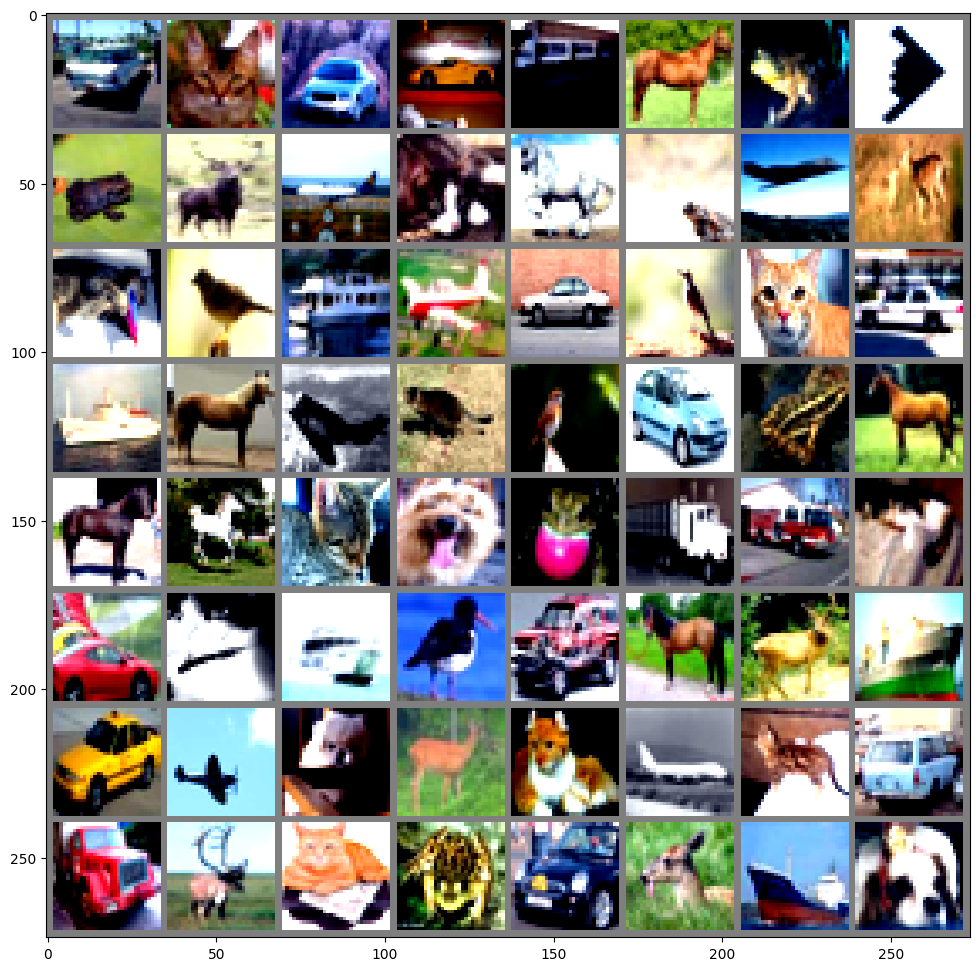

In [5]:
images, labels = next(iter(train_dataloader))

plt.figure(figsize=(12, 12))
# create grid of images
img_grid = torchvision.utils.make_grid(images)
# show images
matplotlib_imshow(img_grid, one_channel=False)

In [5]:
def plot_history(train_history, val_history, title="loss"):
    plt.figure()
    plt.title(title)
    plt.plot(train_history, label="train", zorder=1)

    points = np.array(val_history)
    steps = list(
        range(0, len(train_history) + 1, int(len(train_history) / len(val_history)))
    )[1:]

    plt.scatter(
        steps, val_history, marker="+", s=180, c="orange", label="val", zorder=2
    )
    plt.xlabel("train steps")

    plt.legend(loc="best")
    plt.grid()

    plt.show()

### Задание
В качестве бейзлайна постройте следующую архитектуру из 1 VGG блока:

1) VGG блок с 16 каналами:
* свёрточный слой с 16 выходными каналами и ядром 3x3, паддингом и нелинейностью ReLU
* свёрточный слой с 16 выходными каналами и ядром 3x3, паддингом и нелинейностью ReLU
* Max pooling c ядром 2x2 и шагом 2

2) Полносвязный слой с 128 выходами и нелинейностью ReLU

3) Полносвязный слой с 10 выходами и Softmax

In [6]:
class ModelBaseline(nn.Module):
    def __init__(self, in_channels=3, num_classes=10,
                 input_size=32, activation=nn.ReLU):
        super().__init__()
        self.activation = activation(inplace=True)   # экземпляр, а не класс

        self.vgg_block = nn.Sequential(
            nn.Conv2d(in_channels, 16, 3, padding=1),
            self.activation,
            nn.Conv2d(16, 16, 3, padding=1),
            self.activation,
            nn.MaxPool2d(2, 2),
        )

        feat = 16 * (input_size // 2) * (input_size // 2)
        self.fc1 = nn.Linear(feat, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.vgg_block(x).flatten(1)
        x = self.activation(self.fc1(x))
        logits = self.fc2(x)
        return torch.log_softmax(logits, dim=1)


In [4]:
def train(model, criterion, optimizer, train_dataloader, val_dataloader, n_epochs=2):
    for epoch in range(n_epochs):
        # тренировка
        train_epoch_loss, train_epoch_true_hits = torch.empty(0), torch.empty(0)
        model.train()
        for imgs, labels in tqdm(
            train_dataloader, desc=f"Training, epoch {epoch}", leave=False
        ):
            imgs, labels = imgs.to(device), labels.to(device)

            y_pred = model(imgs)
            loss = criterion(y_pred, labels)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            # log loss for the current epoch and the whole training history
            train_epoch_loss = torch.cat(
                (train_epoch_loss, loss.cpu().unsqueeze(0) / labels.cpu().size(0))
            )

            # log accuracy for the current epoch and the whole training history
            pred_classes = torch.argmax(y_pred.cpu(), dim=-1)
            train_epoch_true_hits = torch.cat(
                (
                    train_epoch_true_hits,
                    (pred_classes == labels.cpu()).sum().unsqueeze(0),
                )
            )

        # валидация
        val_epoch_loss, val_epoch_true_hits = torch.empty(0), torch.empty(0)
        model.eval()
        with torch.no_grad():
            for imgs, labels in tqdm(
                val_dataloader, desc=f"Validating, epoch {epoch}", leave=False
            ):
                imgs, labels = imgs.to(device), labels.to(device)

                y_pred = model(imgs)
                loss = criterion(y_pred, labels)
                val_epoch_loss = torch.cat(
                    (val_epoch_loss, loss.cpu().unsqueeze(0) / labels.cpu().size(0))
                )

                pred_classes = torch.argmax(y_pred.cpu(), dim=-1)
                val_epoch_true_hits = torch.cat(
                    (
                        val_epoch_true_hits,
                        (pred_classes == labels.cpu()).sum().unsqueeze(0),
                    )
                )


        print("Train loss:", train_epoch_loss.mean().item())
        print(
            "Train acc:",
            (
                train_epoch_true_hits.sum()
                / train_epoch_true_hits.size(0)
                / train_dataloader.batch_size
            ).item(),
        )
        print("Val loss:", val_epoch_loss.mean().item())
        print(
            "Val acc:",
            (
                val_epoch_true_hits.sum()
                / val_epoch_true_hits.size(0)
                / val_dataloader.batch_size
            ).item(),
        )

In [9]:
model_baseline = ModelBaseline().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model_baseline.parameters(), lr=0.001, momentum=0.9)

train(model_baseline, criterion, optimizer, train_dataloader, val_dataloader)

Training, epoch 0:   0%|          | 0/782 [00:17<?, ?it/s]

Validating, epoch 0:   0%|          | 0/157 [00:15<?, ?it/s]

Train loss: 0.03108906000852585
Train acc: 0.2964354157447815
Val loss: 0.026879699900746346
Val acc: 0.40455812215805054


Training, epoch 1:   0%|          | 0/782 [00:18<?, ?it/s]

Validating, epoch 1:   0%|          | 0/157 [00:15<?, ?it/s]

Train loss: 0.024471811950206757
Train acc: 0.44751039147377014
Val loss: 0.023037508130073547
Val acc: 0.47850319743156433


### Визуализируем параметры сети

In [17]:
from mne.viz import plot_filter

In [18]:
model_baseline.cpu()

ModelBaseline(
  (vgg_block): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc1): Linear(in_features=4096, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

In [22]:
plot_filter(model_baseline.vgg_block[0], sfreq=256.0)

ValueError: Unknown dtype object.

In [ ]:
plot_filter(model_baseline.vgg_block[1], single_channel=True)

In [ ]:
plot_filter(model_baseline.vgg_block[2], single_channel=True)

### Задание

Поэкспериментируйте с функциями активации сети. Попробуйте заменить ReLU на LeakyReLU, ELU или SELU. Как замена влияет на качество и скорость сходимости?

In [9]:
model_baseline2 = ModelBaseline(activation=nn.LeakyReLU).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model_baseline2.parameters(), lr=0.001, momentum=0.9)

train(model_baseline2, criterion, optimizer, train_dataloader, val_dataloader)

Training, epoch 0:   0%|          | 0/782 [00:17<?, ?it/s]

Validating, epoch 0:   0%|          | 0/157 [00:15<?, ?it/s]

Train loss: 0.030040299519896507
Train acc: 0.3183344006538391
Val loss: 0.025920921936631203
Val acc: 0.42446258664131165


Training, epoch 1:   0%|          | 0/782 [00:18<?, ?it/s]

Validating, epoch 1:   0%|          | 0/157 [00:16<?, ?it/s]

Train loss: 0.023858344182372093
Train acc: 0.4618566036224365
Val loss: 0.02235695719718933
Val acc: 0.49432721734046936


In [9]:
model_baseline3 = ModelBaseline(activation=nn.ELU).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model_baseline3.parameters(), lr=0.001, momentum=0.9)

train(model_baseline3, criterion, optimizer, train_dataloader, val_dataloader)

Training, epoch 0:   0%|          | 0/782 [00:17<?, ?it/s]

Validating, epoch 0:   0%|          | 0/157 [00:15<?, ?it/s]

Train loss: 0.027610674500465393
Train acc: 0.38117408752441406
Val loss: 0.023829089477658272
Val acc: 0.4727309048175812


Training, epoch 1:   0%|          | 0/782 [00:18<?, ?it/s]

Validating, epoch 1:   0%|          | 0/157 [00:16<?, ?it/s]

Train loss: 0.022122398018836975
Train acc: 0.4986213147640228
Val loss: 0.021387923508882523
Val acc: 0.5206010937690735


In [9]:
model_baseline4 = ModelBaseline(activation=nn.SELU).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model_baseline4.parameters(), lr=0.001, momentum=0.9)

train(model_baseline4, criterion, optimizer, train_dataloader, val_dataloader)

Training, epoch 0:   0%|          | 0/782 [00:17<?, ?it/s]

Validating, epoch 0:   0%|          | 0/157 [00:14<?, ?it/s]

Train loss: 0.026255270466208458
Train acc: 0.41126519441604614
Val loss: 0.0236765556037426
Val acc: 0.46516719460487366


Training, epoch 1:   0%|          | 0/782 [00:18<?, ?it/s]

Validating, epoch 1:   0%|          | 0/157 [00:16<?, ?it/s]

Train loss: 0.021178284659981728
Train acc: 0.5210997462272644
Val loss: 0.02020338922739029
Val acc: 0.5442874431610107


C LeakyReLU работает немного лучше)

## 2. Аугментации

Аугментация данных - очень мощный процесс, который позволяет увеличить количество тренировочных данных. С помощью поворотов, отражения, добавления шума, сдвигов и других преобразований, картинка немного меняется, однако сохраняет свою прежнюю метку. С помощью функции Compose можно объединять несколько трансформаций изображения, а потом применять их при чтении датасета. Полный список аугментаций доступен [тут](https://pytorch.org/vision/stable/transforms.html). Изучите его и поэкспериментируйте с различными трансформациями изображения.

Довольно мощным и эффективным инструментом для аугментаций на картинках является библиотека `albumentations`. Можете поэкспериментировать с ней сами.

In [5]:
from torchvision.transforms import InterpolationMode

transform = transforms.Compose([
    transforms.ColorJitter(hue=0.05, saturation=0.05),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20, interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
]
)

base_transform = torchvision.transforms.Compose(
    [
        torchvision.transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ]
)

cifar_train = torchvision.datasets.CIFAR10(
    root="./cifar", train=True, download=False, transform=transform
)
cifar_val = torchvision.datasets.CIFAR10(
    root="./cifar", train=False, download=False, transform=base_transform
)

train_dataloader = torch.utils.data.DataLoader(
    cifar_train, batch_size=64, shuffle=True, num_workers=4
)
val_dataloader = torch.utils.data.DataLoader(
    cifar_val, batch_size=64, shuffle=False, num_workers=4
)

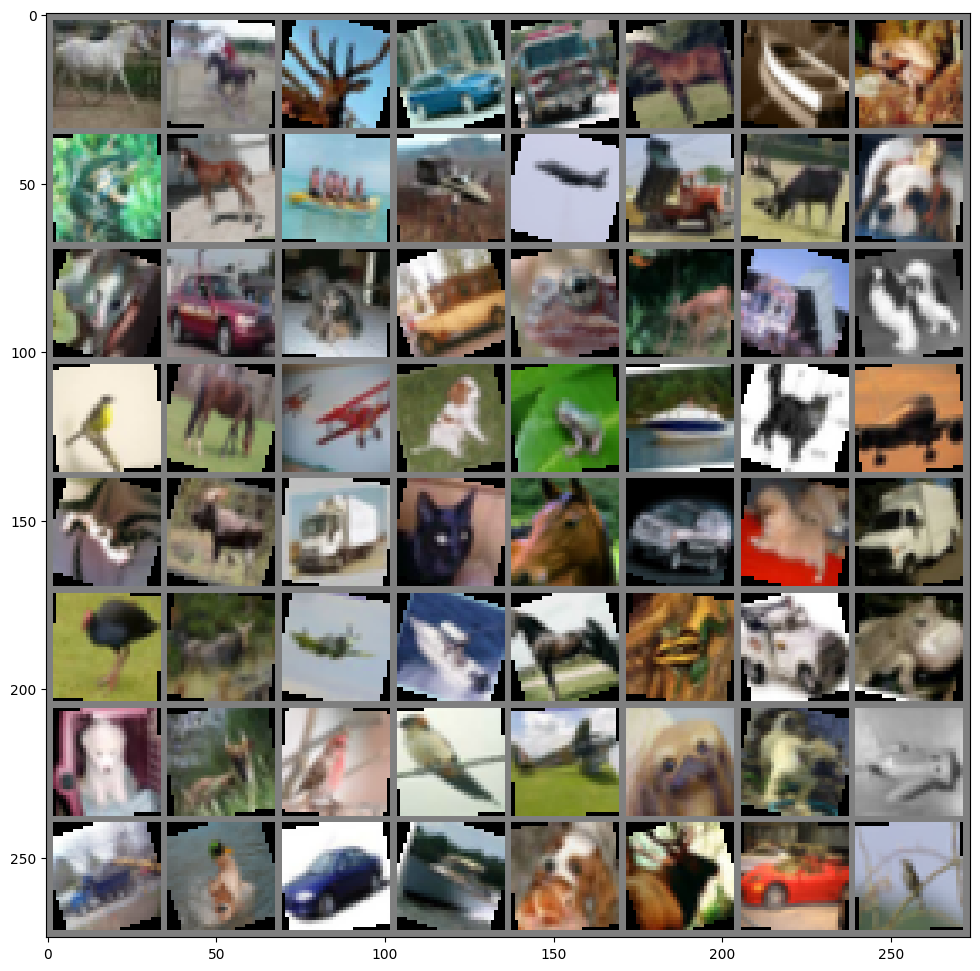

In [10]:
images, labels = next(iter(train_dataloader))

plt.figure(figsize=(12, 12))
# create grid of images
img_grid = torchvision.utils.make_grid(images)
# show images
matplotlib_imshow(img_grid, one_channel=False)

In [11]:
model_baseline = ModelBaseline().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model_baseline.parameters(), lr=0.001, momentum=0.9)

train(model_baseline, criterion, optimizer, train_dataloader, val_dataloader)

Training, epoch 0:   0%|          | 0/782 [00:17<?, ?it/s]

Validating, epoch 0:   0%|          | 0/157 [00:16<?, ?it/s]

Train loss: 0.034046340733766556
Train acc: 0.2133152186870575
Val loss: 0.030281880870461464
Val acc: 0.31936705112457275


Training, epoch 1:   0%|          | 0/782 [00:20<?, ?it/s]

Validating, epoch 1:   0%|          | 0/157 [00:18<?, ?it/s]

Train loss: 0.027809906750917435
Train acc: 0.3724624216556549
Val loss: 0.02570822648704052
Val acc: 0.4247611463069916


## 3. Регуляризации и нормализации в нейронных сетях

### Dropout
Если сеть имеет сложную архитектуру, то возможно переобучение - процесс, в котором модель слишком сильно подстраивается под тренировочную выборку и потом дает заниженное качество на тестовой. Для борьбы с этим можно использовать Dropout. Идея метода очень проста. На тренировке `torch.nn.Dropout` зануляет каждый элемент входного тензора с вероятностью $p$. На инференсе ничего не зануляется, но, для того, чтобы сохранить масштаб выходов сети, все элементы входного тензора делятся на $1 - p$.

Для стабилизации и ускорения сходимости обучения часто используют батч нормализацию. В **PyTorch** она тоже имплементирована в виде слоя — [`torch.nn.BatchNorm2d`](https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html). Обычно батч нормализацию вставляют между смысловыми блоками нейронной сети, чтобы сохранять распределение данных на всём forward pass. Обратите внимание, что на тренировке выборочные среднее и стандартное отклонение каждый раз заново вычисляются по батчу, а также у слоя есть обучаемых два числовых параметра на каждый канал входного тензора. На инференсе в качестве среднего и дисперсии используются оценки, полученные скользящими средними во время тренировки.

Давайте обучим новую сеть, в которой будет 3 VGG блока и добавим в неё батч нормализацию и дропаут.

In [6]:
model = nn.Sequential(
    nn.Conv2d(3, 16, 3, padding=1),
    nn.BatchNorm2d(16),
    nn.ReLU(),
    nn.Conv2d(16, 16, 3, padding=1),
    nn.BatchNorm2d(16),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),
    nn.Dropout(0.2),
    nn.Conv2d(16, 32, 3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.Conv2d(32, 32, 3, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),
    nn.Dropout(0.2),
    nn.Conv2d(32, 64, 3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.Conv2d(64, 64, 3, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(),
    nn.MaxPool2d(2, 2),
    nn.Dropout(0.2),
    nn.Flatten(),
    nn.Linear(64 * 4 * 4, 128),
    nn.BatchNorm1d(128),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(128, 10),
)

In [7]:
model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

In [8]:
train(model, criterion, optimizer, train_dataloader, val_dataloader)

Training, epoch 0:   0%|          | 0/782 [00:18<?, ?it/s]

Validating, epoch 0:   0%|          | 0/157 [00:15<?, ?it/s]

Train loss: 0.02825581468641758
Train acc: 0.3349384665489197
Val loss: 0.023518266156315804
Val acc: 0.4591958522796631


Training, epoch 1:   0%|          | 0/782 [00:18<?, ?it/s]

Validating, epoch 1:   0%|          | 0/157 [00:19<?, ?it/s]

Train loss: 0.024023041129112244
Train acc: 0.43763986229896545
Val loss: 0.021962670609354973
Val acc: 0.4887539744377136
